# Pose oracle: does body / hand pose add anything to the video features?

Inference has to be video-only, so pose could only enter through a pose estimator run on the video (or a video model
trained to predict pose). Before building that, the oracle test: take Ego-Exo4D's automatic 3D pose (triangulated
from all exo cameras, so better than any single-camera estimate we could produce) and ask whether kinematic features
from it improve the TimeSformer probe. If the oracle doesn't help, estimated pose won't either.

Pose features (`pose_features.py`, per take, 10 Hz, centered on the hips, scaled by torso length, heading-invariant):
joint speeds, acceleration, jerk, jerk/speed (smoothness), stillness, root motion and bounce, joint angles and their
speeds, trunk lean, head and wrist height, pairwise joint distances, left-right coordination, and periodicity
(autocorrelation peak and lag, 0.5-3 Hz band power, spectral entropy) of limb speed and hip height. Hands: wrist and
fingertip speeds, finger extension, fingertip spreads, periodicity.

Same CV as `expert_rating.ipynb`, restricted to the commentary takes that have pose: 4 x 5-fold StratifiedGroupKFold
by participant, PCA-64 per block inside the fold (scenario-centered), scenario one-hot, RidgeCV, predictions centered
within (repeat, fold, scenario); scored by within-scenario Spearman with the level and with held-out experts' ratings
(z-scored per expert); participant bootstrap.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
import pandas as pd
import torch
from scipy.stats import spearmanr

all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
index_of = {t: i for i, t in enumerate(names)}
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)
log_duration = np.log([c["seconds"] for c in all_clips])

rows = []
for t in names:
    for path in sorted((COMMENTARY_ROOT / t).glob("*/data.json")):
        d = json.loads(path.read_text(encoding="utf-8"))
        prof = d.get("proficiency") or {}
        try:
            rating = float(prof.get("rating"))
        except (TypeError, ValueError):
            rating = np.nan
        why = (prof.get("why") or "").strip()
        if why or not np.isnan(rating):
            rows.append({"take_name": t, "expert": d.get("user_id") or path.parent.name, "rating": rating, "why": why})
R = pd.DataFrame(rows)
R["scenario"] = R.take_name.map(lambda t: clip_of[t]["scenario"])
stats = R.groupby("expert").rating.agg(["mean", "std"])
R["rating_z"] = (R.rating - R.expert.map(stats["mean"])) / R.expert.map(stats["std"]).replace(0, np.nan)
take_rating = R.groupby("take_name").rating.mean().reindex(names).to_numpy()
take_z = R.groupby("take_name").rating_z.mean().reindex(names).to_numpy()
print(f"{len(R)} expert entries over {R.take_name.nunique()} takes, {R.expert.nunique()} experts; "
      f"{R.rating.notna().sum()} ratings, {(R.why != '').sum()} whys; takes without a rating: {np.isnan(take_rating).sum()}")
print("ratings:", R.rating.value_counts().sort_index().to_dict())

def within_scenario(x, scen):
    x = np.asarray(x, float).copy()
    for s in np.unique(scen):
        m = scen == s
        x[m] -= np.nanmean(x[m])
    return x

# Held-out-expert rows: (take, expert i) with >= 2 rated experts; target = mean of the other experts.
held_rows = []
for t, grp in R[R.rating.notna()].groupby("take_name"):
    if len(grp) < 2:
        continue
    for i in range(len(grp)):
        others = grp.drop(grp.index[i])
        held_rows.append({"take_name": t, "i": index_of[t], "expert": grp.expert.iloc[i], "one": grp.rating.iloc[i],
                          "one_z": grp.rating_z.iloc[i], "others": others.rating.mean(), "others_z": others.rating_z.mean()})
H = pd.DataFrame(held_rows)
H["scenario"] = scenarios[H.i]
H_scen = H.scenario.to_numpy()
for col in ("one", "one_z", "others", "others_z"):
    H[col + "_c"] = within_scenario(H[col], H_scen)
print(f"{len(H)} held-out-expert rows over {H.take_name.nunique()} takes")
print(f"human: one expert vs others, raw {spearmanr(H.one_c, H.others_c)[0]:.3f}, z-scored {spearmanr(H.one_z_c, H.others_z_c)[0]:.3f}")

5004 expert entries over 1338 takes, 38 experts; 4910 ratings, 5004 whys; takes without a rating: 0
ratings: {1.0: 423, 2.0: 462, 3.0: 499, 4.0: 492, 5.0: 501, 6.0: 483, 7.0: 624, 8.0: 573, 9.0: 479, 10.0: 374}


4879 held-out-expert rows over 1307 takes
human: one expert vs others, raw 0.698, z-scored 0.767


In [3]:
EMBEDDING_DIR = Path("embeddings")
def token_std(view):
    c = torch.load(EMBEDDING_DIR / f"timesformer_k600_{view}8fps_clips.pt", mmap=True)["clips"]["squash"]
    return np.stack([c[t][:, 1, 2].float().mean(0).numpy() for t in names])  # L12 patch-token std, mean over 1 s clips
VIEW = {"exo": token_std("exo"), "ego": token_std("ego")}
REPS = {"TS exo": ["exo"], "TS ego": ["ego"], "TS ego+exo": ["ego", "exo"]}

text_cache = torch.load(EMBEDDING_DIR / "qwen35_base_why_text.pt", mmap=True)
W = R[R.why != ""].reset_index(drop=True)
missing = sum(w not in text_cache for w in W.why)
W = W[[w in text_cache for w in W.why]].reset_index(drop=True)
E = np.stack([text_cache[w][1].float().numpy() for w in W.why])  # Qwen3.5-4B layer 16, mean over the why's tokens
E -= E.mean(0)
E /= np.linalg.norm(E, axis=1, keepdims=True)
W["i"] = W.take_name.map(index_of)
why_rows_of = W.groupby("i").groups
take_text = np.zeros((len(names), E.shape[1]))
for i, idx in why_rows_of.items():
    take_text[i] = E[idx].mean(0)
has_text = np.array([i in why_rows_of for i in range(len(names))])
print(f"video: {({k: v.shape for k, v in VIEW.items()})}; {len(W)} whys embedded ({missing} not in the text cache); "
      f"{has_text.sum()} takes with a why")

video: {'exo': (1338, 768), 'ego': (1338, 768)}; 5004 whys embedded (0 not in the text cache); 1338 takes with a why


#### Pose features

In [4]:
pose = torch.load(EMBEDDING_DIR / "pose_features.pt", weights_only=False)
def pose_matrix(kind):
    have = np.array([t in pose[kind] for t in names])
    X = np.full((len(names), len(pose[f"{kind}_names"])), np.nan, np.float32)
    for i, t in enumerate(names):
        if have[i]:
            X[i] = pose[kind][t]
    return X, have
BODY_X, has_body = pose_matrix("body")
HAND_X, has_hand = pose_matrix("hand")
body_names, hand_names = pose["body_names"], pose["hand_names"]
print(f"commentary takes: {len(names)}; with body pose {has_body.sum()}, with hand pose {has_hand.sum()}")
print(pd.DataFrame({"takes": pd.Series(scenarios).value_counts(), "body pose": pd.Series(scenarios[has_body]).value_counts(),
                    "hand pose": pd.Series(scenarios[has_hand]).value_counts()}).fillna(0).astype(int))
cov = BODY_X[has_body, body_names.index("coverage")]
print(f"body pose frame coverage: median {np.median(cov):.2f}, 10th pct {np.percentile(cov, 10):.2f}")

commentary takes: 1338; with body pose 750, with hand pose 301
               takes  body pose  hand pose
Basketball       379        329         80
Cooking           91         68         66
Dance            290        249         92
Music            118         67         61
Rock Climbing    413          2          0
Soccer            47         35          2
body pose frame coverage: median 0.99, 10th pct 0.57


#### Cross-validated probes on the takes with pose

Blocks: `video` = TS ego+exo token std (PCA-64 each view), `exo` = TS exo only, `body` / `hand` = pose features
(standardized, PCA-64 inside the fold). Each subset (body, hand) gets its own CV so every row is scored on exactly the
same takes.

In [5]:
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS, PCA_DIMS = 4, 5, 64
TARGETS = {"level": scores.astype(float), "rating z": take_z}
BLOCK_SOURCES = {"ego": VIEW["ego"], "exo": VIEW["exo"], "body": BODY_X, "hand": HAND_X}

def run_cv(subset, reps):
    idx = np.flatnonzero(subset)
    counts = pd.Series(scenarios[idx]).value_counts()
    idx = idx[np.isin(scenarios[idx], counts[counts >= 20].index)]  # drop scenarios with almost no pose (Rock Climbing: 2)
    sc, part, lvl = scenarios[idx], participants[idx], scores[idx]
    scen_names = np.unique(sc)
    def block(name, fit):
        X = BLOCK_SOURCES[name][idx].astype(np.float64)
        rows = np.zeros(len(idx), bool); rows[fit] = True
        for s in scen_names:  # scenario-centering with fit-fold means; missing values -> the fit mean (0 after centering)
            m = sc == s
            mu = np.nanmean(X[rows & m], 0)
            mu = np.where(np.isfinite(mu), mu, 0)
            X[m] -= mu
        X = np.where(np.isfinite(X), X, 0)
        X = StandardScaler().fit(X[fit]).transform(X)
        X = np.clip(X, -6, 6)
        return PCA(min(PCA_DIMS, X.shape[1]), svd_solver="full").fit(X[fit]).transform(X)
    pred = {(r, t): np.full((N_REPEATS, len(idx)), np.nan) for r in reps for t in TARGETS}
    fold_of = np.zeros((N_REPEATS, len(idx)), int)
    for repeat in range(N_REPEATS):
        folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(idx)), lvl, part)
        for fold, (fit, held) in enumerate(folds):
            fold_of[repeat, held] = fold
            onehot = OneHotEncoder(handle_unknown="ignore").fit(sc[fit][:, None]).transform(sc[:, None]).toarray()
            cache = {}
            for rep, blocks in reps.items():
                parts = [onehot]
                for b in blocks:
                    if b == "duration":
                        d = log_duration[idx][:, None].copy()
                        for s in scen_names:
                            d[sc == s] -= d[fit][sc[fit] == s].mean()
                        parts += [d * (sc == s)[:, None] for s in scen_names]
                    else:
                        if b not in cache:
                            cache[b] = block(b, fit)
                        parts.append(cache[b])
                X = StandardScaler().fit(np.hstack(parts)[fit]).transform(np.hstack(parts))
                for target, y in TARGETS.items():
                    yy = y[idx]
                    ok = fit[~np.isnan(yy[fit])]
                    pred[(rep, target)][repeat, held] = RidgeCV(alphas=np.logspace(-2, 6, 17)).fit(X[ok], yy[ok]).predict(X[held])
    for key, p in pred.items():  # center within (repeat, fold, scenario), then average over repeats
        for r in range(N_REPEATS):
            for f in range(N_FOLDS):
                for s in scen_names:
                    g = (fold_of[r] == f) & (sc == s)
                    p[r, g] -= np.nanmean(p[r, g])
        pred[key] = p.mean(0)
    return idx, pred

BODY_REPS = {"scenario only": [], "duration only": ["duration"], "body pose": ["body"], "TS exo": ["exo"],
             "TS exo + body": ["exo", "body"], "TS ego+exo": ["ego", "exo"], "TS ego+exo + body": ["ego", "exo", "body"]}
HAND_REPS = {"scenario only": [], "duration only": ["duration"], "hand pose": ["hand"], "body + hand pose": ["body", "hand"],
             "TS ego+exo": ["ego", "exo"], "TS ego+exo + hand": ["ego", "exo", "hand"], "TS ego+exo + body + hand": ["ego", "exo", "body", "hand"]}
runs = {"body": run_cv(has_body, BODY_REPS)}
print("body CV done", flush=True)
runs["hand"] = run_cv(has_hand & has_body, HAND_REPS)
print("hand CV done", flush=True)

body CV done


hand CV done


#### Results: within-scenario Spearman, vs level and vs held-out experts (z)

In [6]:
N_BOOTSTRAP = 1000
def sp(a, b):
    return spearmanr(a, b)[0] if np.std(a) > 1e-12 and np.std(b) > 1e-12 else 0.0

def evaluate(run, reps):
    idx, pred = run
    pos = {t: k for k, t in enumerate(idx)}
    sc, part = scenarios[idx], participants[idx]
    lvl_c = within_scenario(scores[idx], sc)
    Hs = H[H.i.isin(idx)].copy()
    Hs["k"] = Hs.i.map(pos)
    # re-center the experts' targets within scenario on this subset
    for col in ("one_z", "others_z"):
        Hs[col + "_s"] = within_scenario(Hs[col], Hs.scenario.to_numpy())
    hk, hpart, hscen = Hs.k.to_numpy(), part[Hs.k.to_numpy()], Hs.scenario.to_numpy()
    upart = np.unique(part)
    rng = np.random.default_rng(0)
    draws = [rng.choice(upart, len(upart)) for _ in range(N_BOOTSTRAP)]
    t_rows = {p: np.flatnonzero(part == p) for p in upart}
    h_rows = {p: np.flatnonzero(hpart == p) for p in upart}
    t_res = [np.concatenate([t_rows[p] for p in d]) for d in draws]
    h_res = [np.concatenate([h_rows[p] for p in d if p in h_rows] or [np.array([], int)]) for d in draws]
    y_h = Hs.others_z_s.to_numpy()
    res = {}
    def both(x_take, x_rows):
        return {"vs level": (sp(x_take, lvl_c), np.array([sp(x_take[r], lvl_c[r]) for r in t_res])),
                "vs experts z": (sp(x_rows, y_h), np.array([sp(x_rows[r], y_h[r]) for r in h_res]))}
    res["human: one expert"] = {"vs experts z": (sp(Hs.one_z_s.to_numpy(), y_h),
                                                  np.array([sp(Hs.one_z_s.to_numpy()[r], y_h[r]) for r in h_res]))}
    for rep in reps:
        res[(rep, "level")] = both(pred[(rep, "level")], pred[(rep, "level")][hk])
        res[(rep, "rating z")] = both(pred[(rep, "rating z")], pred[(rep, "rating z")][hk])
    per = {}
    for s in np.unique(sc):
        m, mh = sc == s, hscen == s
        per[s] = {"takes": int(m.sum()), "human": sp(Hs.one_z_s.to_numpy()[mh], y_h[mh]) if mh.sum() > 5 else np.nan}
        for rep in reps:
            x = pred[(rep, "rating z")]
            per[s][rep] = sp(x[hk][mh], y_h[mh]) if mh.sum() > 5 else np.nan
            per[s][rep + " | level"] = sp(pred[(rep, "level")][m], lvl_c[m])
    return res, per

def fmt(m):
    v, b = m
    lo, hi = np.nanquantile(b, [0.025, 0.975])
    return f"{v:+.3f} [{lo:+.3f}, {hi:+.3f}]"

def diff(res, a, b, col):
    d = res[a][col][1] - res[b][col][1]
    lo, hi = np.nanquantile(d, [0.025, 0.975])
    return f"{res[a][col][0] - res[b][col][0]:+.3f} [{lo:+.3f}, {hi:+.3f}]" + ("  *" if lo > 0 or hi < 0 else "")

evals = {}
for kind, reps in (("body", BODY_REPS), ("hand", HAND_REPS)):
    res, per = evaluate(runs[kind], reps)
    evals[kind] = (res, per)
    idx = runs[kind][0]
    print(f"\n=== takes with {kind} pose: {len(idx)} takes, {len(np.unique(participants[idx]))} participants")
    print(f"{'representation':<28}{'level-trained, vs level':>28}{'rating-trained, vs experts z':>32}")
    print(f"{'human: one expert':<28}{'':>28}{fmt(res['human: one expert']['vs experts z']):>32}")
    for rep in reps:
        print(f"{rep:<28}{fmt(res[(rep, 'level')]['vs level']):>28}{fmt(res[(rep, 'rating z')]['vs experts z']):>32}")
    print("paired differences (* = 95% CI excludes 0)")
    pairs = ([("TS ego+exo + body", "TS ego+exo"), ("TS exo + body", "TS exo"), ("body pose", "duration only"), ("body pose", "TS ego+exo")]
             if kind == "body" else [("TS ego+exo + hand", "TS ego+exo"), ("TS ego+exo + body + hand", "TS ego+exo"), ("hand pose", "duration only")])
    for a, b in pairs:
        print(f"  {a + ' - ' + b:<46} level {diff(res, (a, 'level'), (b, 'level'), 'vs level')}   "
              f"experts z {diff(res, (a, 'rating z'), (b, 'rating z'), 'vs experts z')}")
    table = pd.DataFrame(per).T
    cols = ["takes", "human", *reps]
    print("per scenario, rating-trained vs held-out experts (z):")
    print(table[cols].drop(columns=["scenario only"]).round(2).to_string())
    print("per scenario, level-trained vs level:")
    print(table[[r + " | level" for r in reps if r != "scenario only"]].round(2).rename(columns=lambda c: c[:-8]).to_string())


=== takes with body pose: 748 takes, 157 participants
representation                   level-trained, vs level    rating-trained, vs experts z
human: one expert                                                +0.739 [+0.687, +0.775]
scenario only                    +0.000 [+0.000, +0.000]         +0.000 [+0.000, +0.000]
duration only                    +0.221 [+0.090, +0.341]         +0.273 [+0.146, +0.381]
body pose                        +0.139 [-0.014, +0.292]         +0.522 [+0.425, +0.605]
TS exo                           +0.350 [+0.187, +0.489]         +0.407 [+0.228, +0.547]
TS exo + body                    +0.289 [+0.136, +0.426]         +0.533 [+0.409, +0.626]
TS ego+exo                       +0.414 [+0.261, +0.535]         +0.470 [+0.315, +0.599]
TS ego+exo + body                +0.326 [+0.160, +0.466]         +0.558 [+0.438, +0.656]
paired differences (* = 95% CI excludes 0)
  TS ego+exo + body - TS ego+exo                 level -0.088 [-0.145, -0.031]  *   experts z +0.089 


=== takes with hand pose: 289 takes, 87 participants
representation                   level-trained, vs level    rating-trained, vs experts z
human: one expert                                                +0.696 [+0.610, +0.755]
scenario only                    +0.000 [+0.000, +0.000]         +0.000 [+0.000, +0.000]
duration only                    +0.197 [+0.028, +0.356]         +0.294 [+0.149, +0.440]
hand pose                        +0.102 [-0.038, +0.237]         +0.386 [+0.236, +0.505]
body + hand pose                 +0.037 [-0.109, +0.189]         +0.471 [+0.329, +0.582]
TS ego+exo                       +0.068 [-0.168, +0.280]         +0.398 [+0.213, +0.543]
TS ego+exo + hand                +0.104 [-0.105, +0.293]         +0.433 [+0.257, +0.564]
TS ego+exo + body + hand         +0.093 [-0.098, +0.262]         +0.482 [+0.321, +0.604]
paired differences (* = 95% CI excludes 0)
  TS ego+exo + hand - TS ego+exo                 level +0.036 [-0.052, +0.129]   experts z +0.035 [-0.

#### Which pose features carry the signal?

Univariate within-scenario Spearman of each body feature with the mean expert rating (z), per scenario with enough
takes, against the same for take duration. Exploratory (no multiple-comparison correction), meant to show *what* the
pose sees, not to select features.

In [7]:
z_c = within_scenario(take_z, scenarios)
for s in ["Basketball", "Dance", "Music", "Cooking", "Soccer"]:
    m = has_body & (scenarios == s) & np.isfinite(take_z)
    if m.sum() < 40:
        continue
    r = pd.Series({n: sp(np.nan_to_num(BODY_X[m, j], nan=np.nanmedian(BODY_X[m, j])), z_c[m]) for j, n in enumerate(body_names)})
    top = r.reindex(r.abs().sort_values(ascending=False).index)[:6]
    print(f"{s} ({m.sum()} takes; duration {sp(log_duration[m], z_c[m]):+.2f}): " + "; ".join(f"{k} {v:+.2f}" for k, v in top.items()))

Basketball (329 takes; duration -0.30): dist left-hip-right-hip mean -0.54; root vertical speed std +0.54; root vertical speed p90 +0.52; root vertical speed mean +0.50; angle left knee std +0.50; angle right knee std +0.49
Dance (249 takes; duration -0.33): angle speed right shoulder p50 +0.63; speed right-elbow p50 +0.58; angle speed right shoulder mean +0.57; angle speed left shoulder mean +0.57; speed left-elbow p50 +0.55; angle speed left shoulder p90 +0.55


Music (67 takes; duration -0.25): angle left shoulder p10 +0.49; dist right-wrist-right-hip mean +0.47; angle left shoulder mean +0.44; angle left shoulder p50 +0.42; dist left-elbow-left-hip mean +0.39; dist left-wrist-left-hip mean +0.37


Cooking (68 takes; duration -0.47): head height p10 +0.52; angle right shoulder p10 +0.50; dist right-elbow-left-hip mean +0.49; acc ankles p50 +0.48; head height p50 +0.47; dist left-elbow-right-elbow mean +0.46


C:\Users\darkn\AppData\Local\Temp\ipykernel_32740\1717692252.py:3: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0] if np.std(a) > 1e-12 and np.std(b) > 1e-12 else 0.0


#### Figure

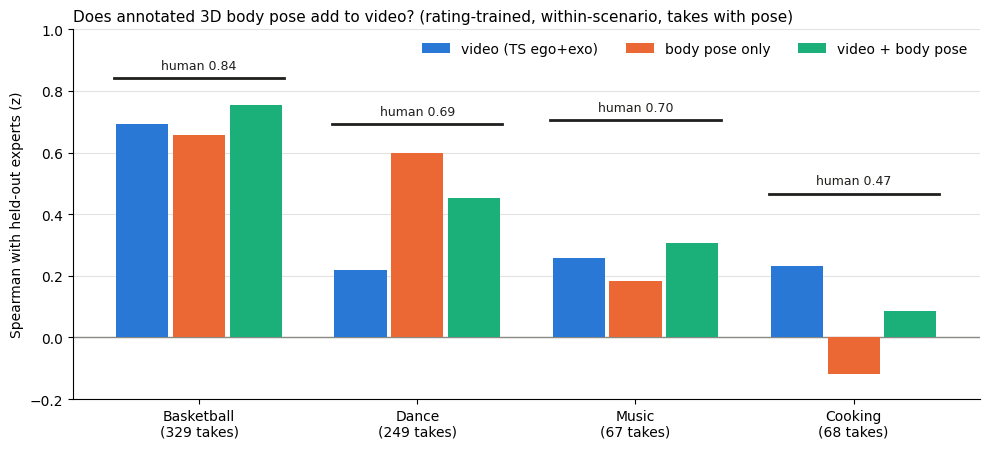

In [8]:
import matplotlib.pyplot as plt
res, per = evals["body"]
shown = [s for s in ["Basketball", "Dance", "Music", "Cooking", "Soccer"] if s in per and per[s]["takes"] >= 40]
series = [("TS ego+exo", "video (TS ego+exo)", "#2a78d6"), ("body pose", "body pose only", "#eb6834"),
          ("TS ego+exo + body", "video + body pose", "#1baf7a")]
fig, ax = plt.subplots(figsize=(10, 4.6))
w = 0.26
for k, (rep, label, color) in enumerate(series):
    xs = np.arange(len(shown)) + (k - 1) * w
    vals = [per[s][rep] for s in shown]
    ax.bar(xs, vals, w * 0.92, color=color, label=label, zorder=3)
for j, s in enumerate(shown):
    ax.plot([j - 1.5 * w, j + 1.5 * w], [per[s]["human"]] * 2, color="#1f1f1d", lw=2, zorder=4)
    ax.text(j, per[s]["human"] + 0.02, f"human {per[s]['human']:.2f}", ha="center", va="bottom", fontsize=9, color="#1f1f1d")
ax.set_xticks(range(len(shown)), [f"{s}\n({per[s]['takes']} takes)" for s in shown])
ax.axhline(0, color="#8a8984", lw=1)
ax.set_ylabel("Spearman with held-out experts (z)")
ax.set_ylim(min(-0.2, ax.get_ylim()[0]), 1.0)
ax.grid(axis="y", color="#e4e3df", zorder=0)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=3)
ax.set_title("Does annotated 3D body pose add to video? (rating-trained, within-scenario, takes with pose)", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/pose_oracle.png", dpi=150)
plt.show()